In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/Neha-Shrestha/EDA-Roller-Coaster/main/coaster_db.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1087, 56)


,coaster_name,Length,Speed,Location,Status,Opening date,Type,Manufacturer,Height restriction,Model,...,speed1,speed2,speed1_value,speed1_unit,speed_mph,height_value,height_unit,height_ft,Inversions_clean,Gforce_clean
0,Switchback Railway,600 ft (180 m),6 mph (9.7 km/h),Coney Island,Removed,"June 16, 1884",Wood,LaMarcus Adna Thompson,NaN,Lift Packed,...,6 mph,9.7 km/h,6.0,mph,6.0,50.0,ft,NaN,0,2.9
1,Flip Flap Railway,NaN,NaN,Sea Lion Park,Removed,1895,Wood,Lina Beecher,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.0
2,Switchback Railway (Euclid Beach Park),NaN,NaN,"Cleveland, Ohio, United States",Closed,NaN,Other,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
3,Loop the Loop (Coney Island),NaN,NaN,Other,Removed,1901,Steel,Edwin Prescott,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN
4,Loop the Loop (Young's Pier),NaN,NaN,Other,Removed,1901,Steel,Edwin Prescott,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1087 entries, 0 to 1086
Data columns (total 56 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   coaster_name                   1087 non-null   object 
 1   Length                         953 non-null    object 
 2   Speed                          937 non-null    object 
 3   Location                       1087 non-null   object 
 4   Status                         874 non-null    object 
 5   Opening date                   837 non-null    object 
 6   Type                           1087 non-null   object 
 7   Manufacturer                   1028 non-null   object 
 8   Height restriction             831 non-null    object 
 9   Model                          744 non-null    object 
 10  Height                         965 non-null    object 
 11  Inversions                     932 non-null    float64
 12  Lift/launch system         

In [4]:
print("Statistical Summary:")
display(df.describe())

Statistical Summary:


,Inversions,year_introduced,latitude,longitude,speed1_value,speed_mph,height_value,height_ft,Inversions_clean,Gforce_clean
count,932.000000,1087.000000,812.000000,812.000000,937.000000,937.000000,965.000000,171.000000,1087.000000,362.000000
mean,1.547210,1994.986201,38.373484,-41.595373,53.850374,48.617289,89.575171,101.996491,1.326587,3.824006
std,2.114073,23.475248,15.516596,72.285227,23.385518,16.678031,136.246444,67.329092,2.030854,0.989998
min,0.000000,1884.000000,-48.261700,-123.035700,5.000000,5.000000,4.000000,13.100000,0.000000,0.800000
25%,0.000000,1989.000000,35.031050,-84.552200,40.000000,37.300000,44.000000,51.800000,0.000000,3.400000
50%,0.000000,2000.000000,40.289800,-76.653600,50.000000,49.700000,79.000000,91.200000,0.000000,4.000000
75%,3.000000,2010.000000,44.799600,2.778100,63.000000,58.000000,113.000000,131.200000,2.000000,4.500000
max,14.000000,2022.000000,63.230900,153.426500,240.000000,149.100000,3937.000000,377.300000,14.000000,12.000000


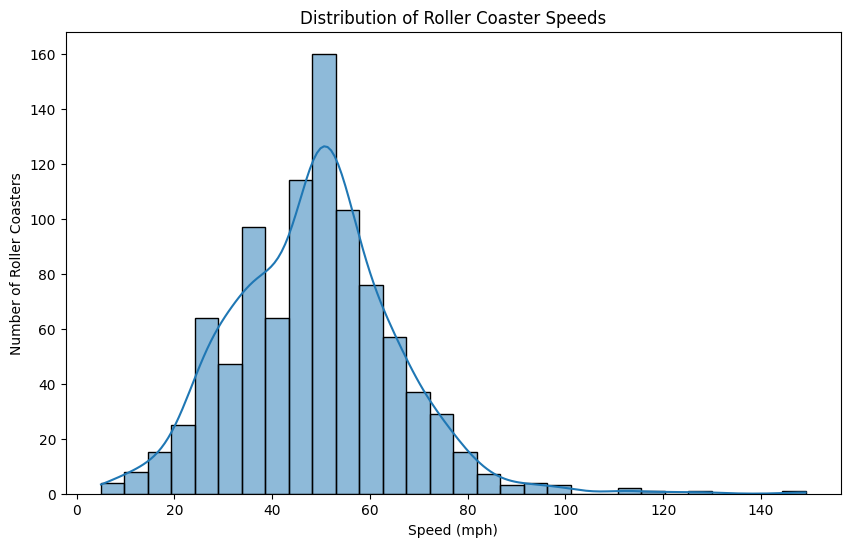

In [5]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['speed_mph'].dropna(),
    bins=30,
    kde=True
)

plt.title('Distribution of Roller Coaster Speeds')
plt.xlabel('Speed (mph)')
plt.ylabel('Number of Roller Coasters')
plt.show()

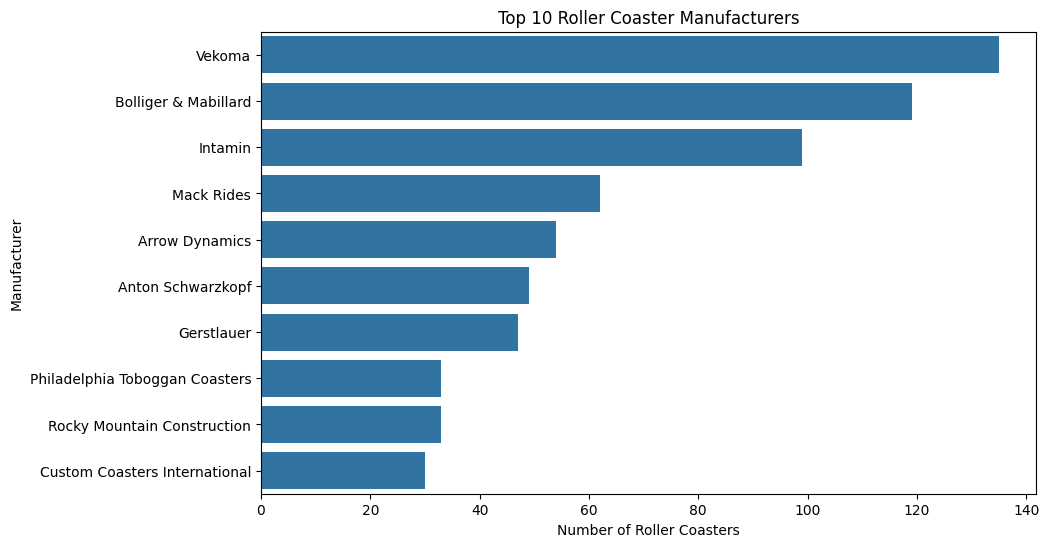

In [6]:
manufacturer_counts = df['Manufacturer'].value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=manufacturer_counts.values,
    y=manufacturer_counts.index
)

plt.title('Top 10 Roller Coaster Manufacturers')
plt.xlabel('Number of Roller Coasters')
plt.ylabel('Manufacturer')
plt.show()

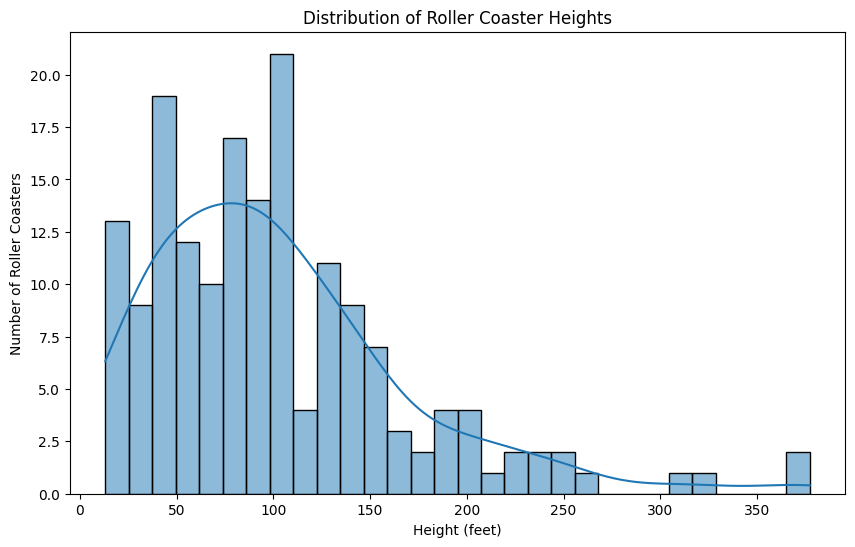

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['height_ft'].dropna(),
    bins=30,
    kde=True
)

plt.title('Distribution of Roller Coaster Heights')
plt.xlabel('Height (feet)')
plt.ylabel('Number of Roller Coasters')
plt.show()

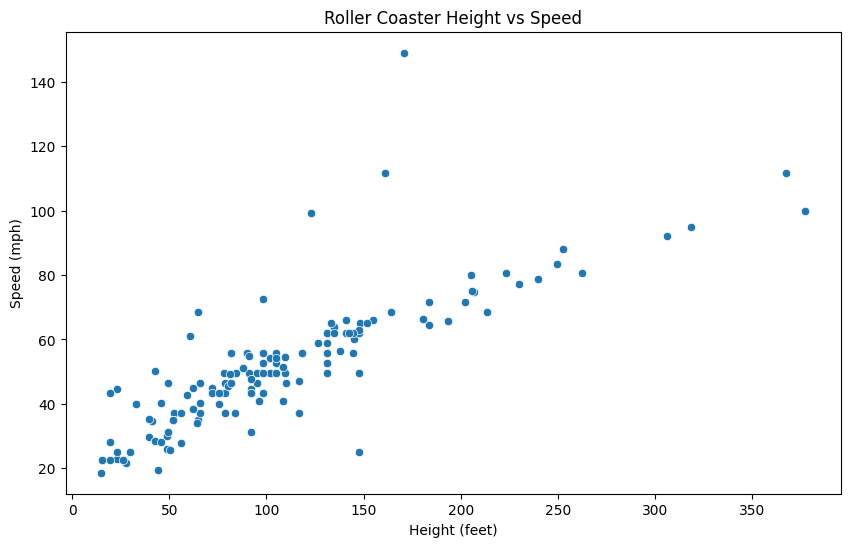

In [8]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='height_ft',
    y='speed_mph'
)

plt.title('Roller Coaster Height vs Speed')
plt.xlabel('Height (feet)')
plt.ylabel('Speed (mph)')
plt.show()

In [9]:
correlation = df[['height_ft', 'speed_mph']].corr()

print("Correlation between Height and Speed:")
display(correlation)

Correlation between Height and Speed:


,height_ft,speed_mph
height_ft,1.000000,0.829404
speed_mph,0.829404,1.000000


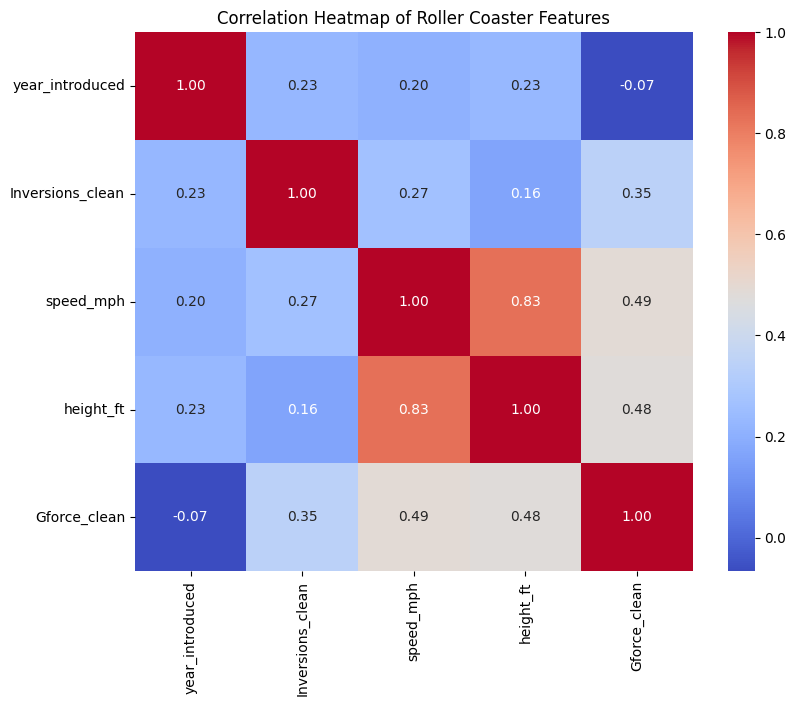

In [10]:
numeric_cols = [
    'year_introduced',
    'Inversions_clean',
    'speed_mph',
    'height_ft',
    'Gforce_clean'
]

correlation_matrix = df[numeric_cols].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap of Roller Coaster Features')
plt.show()

In [11]:
location_counts = df['Location'].value_counts().head(10)

print("Top 10 locations by number of roller coasters:")
display(location_counts)

Top 10 locations by number of roller coasters:


,count
Location,
Other,250
Kings Island,19
Cedar Point,19
Six Flags Magic Mountain,17
Hersheypark,16
Six Flags Great Adventure,15
Carowinds,15
Canada's Wonderland,14
Alton Towers,13


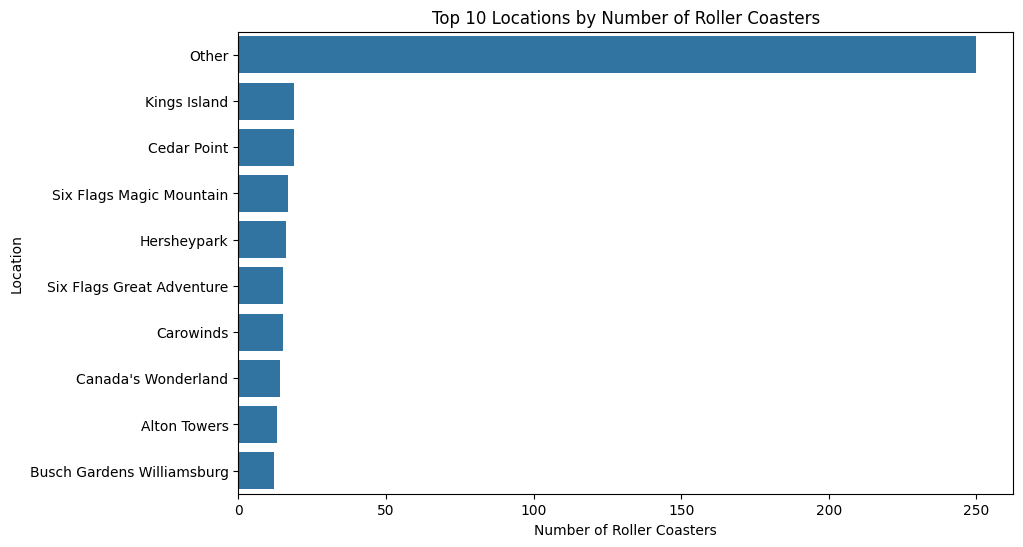

In [12]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=location_counts.values,
    y=location_counts.index
)

plt.title('Top 10 Locations by Number of Roller Coasters')
plt.xlabel('Number of Roller Coasters')
plt.ylabel('Location')
plt.show()

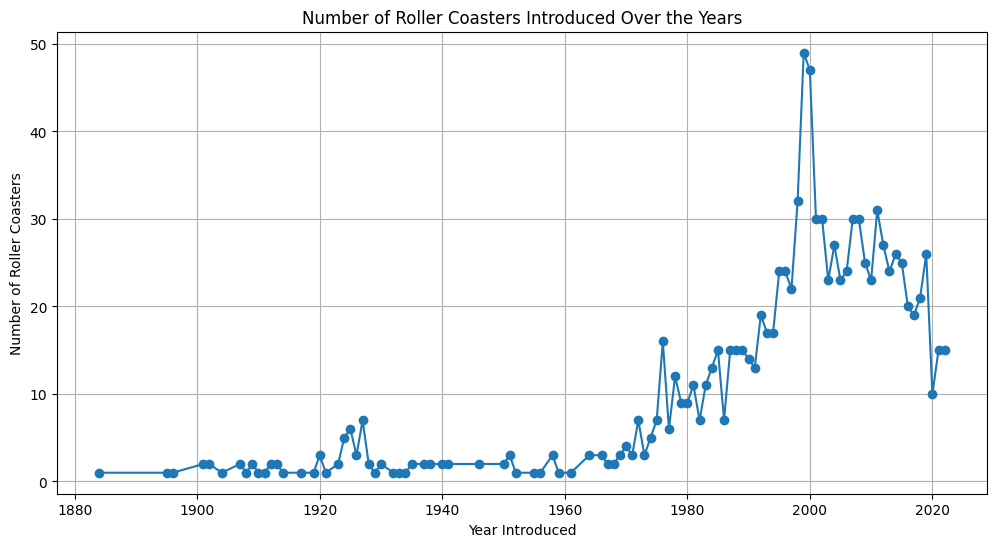

In [13]:
year_counts = df['year_introduced'].value_counts().sort_index()

plt.figure(figsize=(12, 6))

plt.plot(
    year_counts.index,
    year_counts.values,
    marker='o'
)

plt.title('Number of Roller Coasters Introduced Over the Years')
plt.xlabel('Year Introduced')
plt.ylabel('Number of Roller Coasters')
plt.grid(True)
plt.show()

In [14]:
fastest_coasters = df[
    ['coaster_name', 'speed_mph', 'Location', 'Manufacturer']
].dropna(subset=['speed_mph']).sort_values(
    by='speed_mph',
    ascending=False
).head(10)

print("Top 10 Fastest Roller Coasters:")
display(fastest_coasters)

Top 10 Fastest Roller Coasters:


,coaster_name,speed_mph,Location,Manufacturer
812,Formula Rossa,149.1,Ferrari World Abu Dhabi,Intamin
685,Kingda Ka,128.0,Six Flags Great Adventure,Intamin
642,Top Thrill Dragster,120.0,Cedar Point,Intamin
993,Red Force (roller coaster),111.8,Ferrari Land,Intamin
569,Do-Dodonpa,111.8,Fuji-Q Highland,S&S – Sansei Technologies
429,Superman: Escape from Krypton,100.0,Other,Intamin
431,Tower of Terror II,100.0,Dreamworld,Intamin
903,Ring Racer,99.4,Nürburgring,S&S - Sansei Technologies
941,Fury 325,95.0,Carowinds,Bolliger & Mabillard
553,Steel Dragon 2000,95.0,Nagashima Spa Land,D. H. Morgan Manufacturing


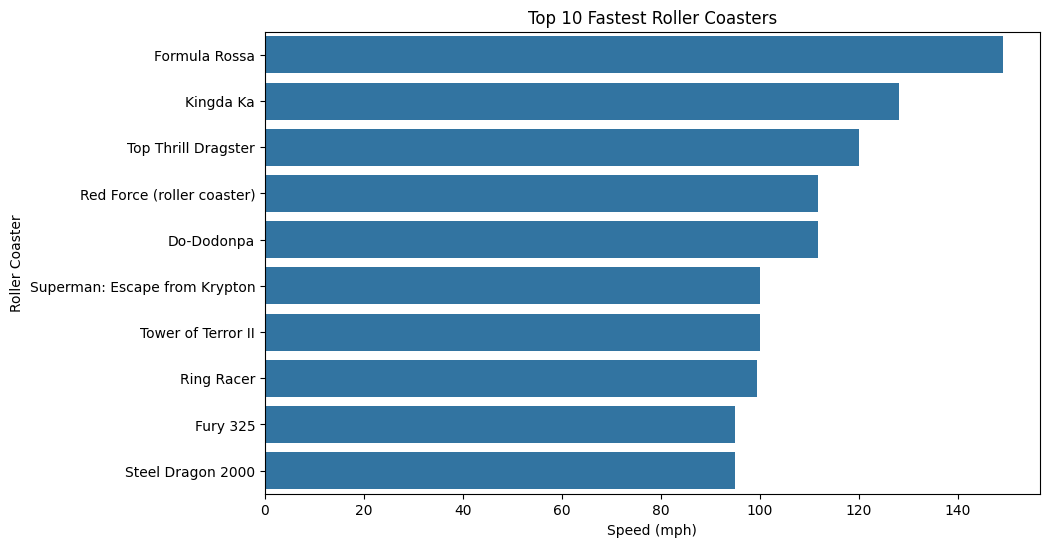

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=fastest_coasters,
    x='speed_mph',
    y='coaster_name'
)

plt.title('Top 10 Fastest Roller Coasters')
plt.xlabel('Speed (mph)')
plt.ylabel('Roller Coaster')
plt.show()

In [16]:
avg_speed_type = (
    df.groupby('Type_Main')['speed_mph']
    .mean()
    .dropna()
    .sort_values(ascending=False)
    .head(10)
)

print("Average Speed by Roller Coaster Type:")
display(avg_speed_type)

Average Speed by Roller Coaster Type:


,speed_mph
Type_Main,
Other,51.132143
Steel,48.575679
Wood,48.387283


## Key Findings

- The dataset contains 1,087 roller coasters with 56 different attributes.
- The dataset contains no duplicate rows.
- Roller coaster speeds show a wide distribution across the dataset.
- The correlation between height and speed is approximately 0.83, indicating a strong positive relationship between the two variables in this dataset.
- Formula Rossa has the highest recorded speed in the dataset at 149.1 mph.
- Among the main coaster types, the average recorded speed is approximately 51.13 mph for Other, 48.58 mph for Steel, and 48.39 mph for Wood.
- The analysis also shows differences in the number of roller coasters across manufacturers, locations, and years of introduction.

## Conclusion

Exploratory Data Analysis was performed on the Roller Coaster Database to understand its structure, distributions, relationships, and trends. Different visualizations and statistical techniques were used to analyze roller coaster speed, height, manufacturers, locations, introduction years, and coaster types.

The analysis revealed a strong positive relationship between roller coaster height and speed, with a correlation of approximately 0.83. The dataset also showed variation in average speed among different coaster types and highlighted the fastest roller coasters in the dataset.

Overall, EDA helped identify important patterns and relationships in the roller coaster data and provided a better understanding of the characteristics of different roller coasters.

In [17]:
df.to_csv("roller_coaster_eda_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!
